# Hình 2 — Kiến trúc HNF–FiLM 1D U-Net (U4)

Notebook **vẽ kiến trúc**, không huấn luyện hoặc đánh giá mô hình. Mã vẽ được nhúng đầy đủ; **không cần GPU, dataset, checkpoint, file ảnh hoặc `src`**. Chỉ dùng Matplotlib và các thành phần có sẵn trong Colab.

**Cách dùng:** mở notebook trên Colab → runtime CPU → **Runtime → Run all**. Hình hiện ngay ở **mục 5**; không tự xuất/tải file. Sửa cấu hình hoặc hàm vẽ, chạy lại các cell liên quan rồi chạy lại mục 5. Xuất/tải là thao tác riêng ở mục 6, chỉ bật khi đã hài lòng.

**Bố cục chữ U:** ba encoder bên trái và ba decoder bên phải nằm đối xứng ở cùng độ phân giải, các nhánh càng xuống càng gần tâm. **Encoder 4 và attention được gom vào một khối bottleneck ở giữa đáy**, không đặt lệch sang một bên. Ba skip chạy ngang thẳng; không có đường vòng dài bao quanh hình.

Mỗi khối decoder gom chuỗi **Up → Concat → HNF**; đầu vào đặc trưng đi từ dưới lên, skip đi vào phép Concat bên trong khối, không đi vào Up. Nhãn trong khối ghi kích thước đầu ra HNF. Các tham chiếu ngắn $e(s)$ cùng chỉ embedding chung phía trên; đây là cách rút gọn đường dây điều kiện, không thêm hay bớt khối FiLM.

**Kiến trúc giữ đúng mã nguồn:** bốn encoder, ba decoder; FiLM tại bốn encoder, không đặt ở decoder hoặc trên đường skip. Đầu ra là Gaussian dự đoán, không phải ECG phục hồi trực tiếp.

**Waveform đầu vào/đầu ra:** bên trái là ECG nhiễu $y$ và trạng thái diffusion $x_s$; bên phải vẫn là Gaussian $\hat\epsilon$, không đổi thành ECG sạch. Mặc định các sóng là **tín hiệu tổng hợp minh họa**, được ghi rõ ngay trên hình; không dùng checkpoint, không phải dữ liệu QTDB/NSTDB hay kết quả đánh giá. Gaussian phía phải chỉ là ký họa cho loại tín hiệu đầu ra, không phải prediction đã tính từ mạng.

**Các chế độ tín hiệu:** `SIGNAL_MODE='illustration'` chạy ngay, không cần dữ liệu; `'symbols'` bỏ waveform; `'provided'` đọc file do bạn cung cấp qua `SIGNALS_NPZ` với các vector `y`, `x_s`, `epsilon_pred` của cùng một mẫu. Chế độ provided chỉ vẽ dữ liệu, không chạy mô hình. Không đưa ECG đã khử nhiễu vào `epsilon_pred`.

**Phân chia nội dung:** Hình 1 mô tả quy trình hệ thống; Hình 2 mô tả mạng với waveform giúp nhận diện loại tín hiệu; Hình 3 trình bày bên trong các khối. Waveform minh họa trong Hình 2 không dùng để kết luận chất lượng phục hồi.

**Khổ paper:** mặc định 7.16 × 6.3 inch, dành cho hình trải **hai cột IEEE**, chữ nội dung 8.2 pt ở kích thước xuất gốc. Không thu cả hình vào một cột vì chữ sẽ nhỏ. Waveform được vẽ bằng đường vector; không dán ảnh sóng raster vào sơ đồ.


## 1. Nội dung kiến trúc và đối chiếu mã nguồn

Nguồn cấu hình: `notebooks/kaggle_ablation_u4_all_noise_512_100ep.ipynb`, lớp `UNet1D` và `SelfAttention1D` được nhúng trong notebook đó. Bản tạo notebook vẽ đã đối chiếu mặc định 2 kênh vào, 80 kênh cơ sở, embedding 128 chiều, 1 kênh ra, attention 4 head và ba phép nối skip. Hash nguồn được lưu tại mục 2 để truy vết; Colab không cần đọc lại file nguồn.

| Khối | Thao tác | Đầu ra (kênh × chiều dài) |
|---|---|---|
| Đầu vào | Nối $x_s$ và ECG quan sát $y$ | $2\times512$ |
| Encoder 1 | HNF → FiLM | $80\times512$ |
| Encoder 2 | Down → HNF → FiLM | $160\times256$ |
| Encoder 3 | Down → HNF → FiLM | $320\times128$ |
| Encoder 4 | Down → HNF → FiLM | $640\times64$ |
| Attention | Self-attention 4 head | $640\times64$ |
| Decoder 3 | Up → nối e3 → HNF | $320\times128$ |
| Decoder 2 | Up → nối e2 → HNF | $160\times256$ |
| Decoder 1 | Up → nối e1 → HNF | $80\times512$ |
| Đầu ra | Conv1D kernel 1 | $1\times512$ |

- $s=\sqrt{\bar\alpha_t}$ đi qua embedding hình sin 128 chiều và điều kiện hóa **bốn encoder**, không phải decoder.
- Mỗi skip lấy đặc trưng encoder **sau FiLM**. Up thực hiện trước khi nối; sau nối có lần lượt 640, 320, 160 kênh rồi HNF giảm về 320, 160, 80.
- Down: Conv1D; Up: ConvTranspose1D; đều kernel 4, stride 2, padding 1.
- Đầu ra $\hat\epsilon$ là Gaussian dự đoán, **không phải ECG phục hồi trực tiếp**; không đặt sigmoid/tanh cuối mạng.
- Attention không có phép cộng residual riêng bên ngoài trong mã nguồn hiện hành.

Đây là sơ đồ phương pháp cho giao thức **512 điểm**, không phải hình kết quả thực nghiệm hay benchmark 3600 điểm.


## 2. Cấu hình hình và vị trí khối

Có thể đổi cỡ chữ, màu, độ nét và tọa độ. `GRAYSCALE=True` cho bản xám; `STRICT_TEXT_CHECK=True` kiểm tra khung/chữ. Mặc định `SIGNAL_MODE=illustration` không cần dữ liệu hoặc checkpoint.

Muốn dùng tín hiệu thật: tải file `.npz` lên Files của Colab, đặt `SIGNAL_MODE=provided` và `SIGNALS_NPZ` thành đường dẫn file. Cần ba vector hữu hạn dài 512: `y` (ECG nhiễu quan sát), `x_s` (trạng thái diffusion) và `epsilon_pred` (Gaussian do mạng dự đoán), cùng một mẫu/mức diffusion. Notebook không tự tạo dữ liệu thay thế nếu thiếu key. Dùng `symbols` để tắt waveform.

In [21]:
from pathlib import Path
from io import BytesIO
import json
import zipfile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle
from matplotlib.path import Path as MplPath
from IPython.display import display, Image

# Chỉ vẽ sơ đồ: không cần GPU, checkpoint, dataset hoặc thư mục src.
MODEL_SPEC = {
    'id': 'U4', 'length': 512, 'input_channels': 2, 'output_channels': 1,
    'base_channels': 80, 'embedding_dim': 128, 'attention_heads': 4,
}
SOURCE_NOTEBOOK = 'notebooks/kaggle_ablation_u4_all_noise_512_100ep.ipynb'
SOURCE_ARCHITECTURE_SHA256 = '52581b6f97118294aff4410e4e1b85204559218befbb10451b6c4708533d2904'

# Khổ hai cột IEEE. Giữ chữ ở cỡ in được, không ép sơ đồ này vào một cột.
FIGURE_WIDTH_IN = 7.16
FIGURE_HEIGHT_IN = 6.3
FONT_SCALE = 1.0
PREVIEW_DPI = 160
PNG_DPI = 600
GRAYSCALE = False
STRICT_TEXT_CHECK = True

# Tọa độ sơ đồ: x trong [0,22], y trong [0,20.3].
# Có thể chỉnh các tọa độ này rồi chạy lại phần vẽ/xem trước.
ENCODER_X = (4.0, 5.3, 6.6)
DECODER_X = (18.0, 16.7, 15.4)  # Cùng thứ tự mức 1, 2, 3.
LEVEL_Y = (12.4, 9.0, 5.6)
BOTTLENECK_Y = 2.1
STAGE_WIDTH, STAGE_HEIGHT = 4.8, 2.1

# Mặc định vẽ tín hiệu tổng hợp MINH HỌA, không phải kết quả huấn luyện.
# 'symbols': chỉ ký hiệu. 'provided': vẽ dữ liệu đã có từ mô hình.
SIGNAL_MODE = 'illustration'
ILLUSTRATION_SEED = 1234
SIGNALS_NPZ = None  # Với provided: .npz có y, x_s, epsilon_pred; mỗi vector dài 512.

INK, MUTED = '#233240', '#526171'
BLUE, GOLD = '#245A81', '#8C651F'
NOISE_COLOR = '#AE4A3A'
HNF_FILL, FILM_FILL = '#E9F1F7', '#FBF2DD'
DECODER_FILL = '#EFF2F5'
ATTN_FILL, GRAY_FILL, WHITE = '#F0EBF5', '#F4F6F8', '#FFFFFF'
if GRAYSCALE:
    BLUE = GOLD = INK
    NOISE_COLOR = INK
    HNF_FILL, FILM_FILL, ATTN_FILL = '#E7E7E7', '#F5F5F5', '#D9D9D9'
    DECODER_FILL = '#F0F0F0'

plt.rcParams.update({
    'font.family': 'DejaVu Serif', 'font.size': 8.2,
    'mathtext.fontset': 'dejavuserif', 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none', 'svg.hashsalt': 'ecg-u4-fig02',
    'savefig.facecolor': WHITE, 'axes.unicode_minus': False,
})
OUTPUT_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'fig02_architecture'
OUTPUT_BASENAME = '2'  # Xuất 2.png / 2.pdf / 2.svg để chèn paper.
print('Matplotlib:', matplotlib.__version__)
print('Chỉ xem trong notebook; chưa ghi hoặc tải file.')


Matplotlib: 3.11.0
Chỉ xem trong notebook; chưa ghi hoặc tải file.


## 3. Hàm vẽ cơ bản

Các khối bo góc biểu diễn một mức xử lý. Mũi tên đen cong tạo luồng chữ U; xanh thẳng là skip; vàng đứt là tham chiếu embedding cho FiLM. Không cần sửa cell này nếu chỉ thay nội dung/đường đi của sơ đồ.

In [22]:
def canvas(width: float, height: float, xmax: float, ymax: float):
    fig = plt.figure(figsize=(width, height), facecolor=WHITE)
    ax = fig.add_axes((0.008, 0.012, 0.984, 0.976))
    ax.set(xlim=(0, xmax), ylim=(0, ymax))
    ax.axis("off")
    return fig, ax


def label(ax, x, y, text, *, size=8.2, color=INK, weight="normal",
          ha="center", va="center", rotation=0):
    return ax.text(x, y, text, fontsize=size * FONT_SCALE, color=color, fontweight=weight,
                   ha=ha, va=va, rotation=rotation, linespacing=1.28,
                   zorder=6)


def box(ax, x, y, width, height, text, *, fill=GRAY_FILL,
        edge=INK, size=8.2, weight="normal"):
    patch = Rectangle((x - width / 2, y - height / 2), width, height,
                      linewidth=0.75, edgecolor=edge, facecolor=fill, zorder=3)
    ax.add_patch(patch)
    artist = label(ax, x, y, text, size=size, weight=weight)
    if not hasattr(ax.figure, "_diagram_box_labels"):
        ax.figure._diagram_box_labels = []
    ax.figure._diagram_box_labels.append((patch, artist))
    return {"left": (x-width/2, y), "right": (x+width/2, y),
            "top": (x, y+height/2), "bottom": (x, y-height/2),
            "center": (x, y)}


def arrow(ax, points, *, color=INK, dashed=False, width=0.8,
          head=7.5, zorder=2):
    codes = [MplPath.MOVETO] + [MplPath.LINETO] * (len(points) - 1)
    ax.add_patch(FancyArrowPatch(path=MplPath(points, codes),
                                 arrowstyle="-|>", mutation_scale=head,
                                 linewidth=width, color=color,
                                 linestyle=(0, (3, 2)) if dashed else "solid",
                                 zorder=zorder, shrinkA=0, shrinkB=0))


def line(ax, points, *, color=INK, dashed=False, width=0.75):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=color, linewidth=width,
            linestyle=(0, (3, 2)) if dashed else "solid", zorder=1)

## 4. Vẽ kiến trúc chữ U đối xứng

Sửa chuỗi chữ hoặc tọa độ ở đây để chỉnh hình. Một khối bottleneck giữa đáy chứa Encoder 4 và attention. Không tách riêng Up/Concat thành nhiều ô nhỏ; thứ tự phép tính được ghi bên trong mỗi khối decoder. Điều kiện dùng tham chiếu ngắn $e(s)$ để tránh đường dây cắt qua skip. Không bỏ timestep hay chuyển FiLM sang decoder.

In [23]:
def check_diagram(fig):
    """Catch out-of-box text and labels outside the canvas at actual print size."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    warnings = []
    for patch, artist in getattr(fig, '_diagram_box_labels', []):
        frame = patch.get_window_extent(renderer)
        text = artist.get_window_extent(renderer)
        if (text.x0 < frame.x0 + 1 or text.x1 > frame.x1 - 1
                or text.y0 < frame.y0 + 1 or text.y1 > frame.y1 - 1):
            warnings.append('Chữ vượt khối: ' + artist.get_text().replace('\n', ' / '))
    boxes = getattr(fig, '_diagram_box_labels', [])
    for index, (first, first_text) in enumerate(boxes):
        first_box = first.get_window_extent(renderer)
        for second, second_text in boxes[index + 1:]:
            second_box = second.get_window_extent(renderer)
            width = min(first_box.x1, second_box.x1) - max(first_box.x0, second_box.x0)
            height = min(first_box.y1, second_box.y1) - max(first_box.y0, second_box.y0)
            if width > 0.5 and height > 0.5:
                warnings.append('Hai khối chồng nhau: '
                                + first_text.get_text().replace('\n', ' / ') + ' & '
                                + second_text.get_text().replace('\n', ' / '))
    bounds = fig.bbox
    for axis in fig.axes:
        for artist in axis.texts:
            text = artist.get_window_extent(renderer)
            if (text.x0 < bounds.x0 or text.x1 > bounds.x1
                    or text.y0 < bounds.y0 or text.y1 > bounds.y1):
                warnings.append('Chữ vượt canvas: ' + artist.get_text().replace('\n', ' / '))
    for warning in warnings:
        print(warning)
    if warnings and STRICT_TEXT_CHECK:
        raise ValueError('Cần chỉnh khung/ngắt dòng hoặc tăng kích thước hình.')
    if not warnings:
        print('Kiểm tra chữ: nằm trong khung và canvas.')
    return warnings


def stage_box(ax, x, y, width, height, text, *, fill=WHITE, size=8.2):
    patch = FancyBboxPatch((x-width/2, y-height/2), width, height,
                           boxstyle='round,pad=0,rounding_size=0.12',
                           linewidth=0.8, edgecolor=INK, facecolor=fill, zorder=3)
    ax.add_patch(patch)
    artist = label(ax, x, y, text, size=size)
    if not hasattr(ax.figure, '_diagram_box_labels'):
        ax.figure._diagram_box_labels = []
    ax.figure._diagram_box_labels.append((patch, artist))
    return {'left': (x-width/2, y), 'right': (x+width/2, y),
            'top': (x, y+height/2), 'bottom': (x, y-height/2), 'center': (x, y)}


def u_arrow(ax, start, end, *, width=1.25):
    mid_y = (start[1] + end[1]) / 2
    path = MplPath([start, (start[0], mid_y), (end[0], mid_y), end],
                   [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4])
    ax.add_patch(FancyArrowPatch(path=path, arrowstyle='-|>', mutation_scale=8,
                                linewidth=width, color=INK, zorder=2,
                                shrinkA=0, shrinkB=0))


def condition_port(ax, target):
    """Named references to one shared e(s), avoiding a wire across every skip."""
    x, y = target
    arrow(ax, [(x-1.3, y), target], color=GOLD, dashed=True, width=0.8)
    label(ax, x-0.85, y+0.43, r'$e(s)$', color=GOLD, size=8.0)


def io_signals():
    """Return explicitly illustrative traces or user-supplied model traces."""
    if SIGNAL_MODE == 'symbols':
        return None
    length = MODEL_SPEC['length']
    if SIGNAL_MODE == 'provided':
        if SIGNALS_NPZ is None:
            raise ValueError('SIGNAL_MODE=provided cần SIGNALS_NPZ; dùng illustration nếu chỉ vẽ minh họa.')
        traces = {}
        with np.load(Path(SIGNALS_NPZ), allow_pickle=False) as data:
            for key in ('y', 'x_s', 'epsilon_pred'):
                if key not in data:
                    raise ValueError(f'File thiếu {key}; cần y, x_s và epsilon_pred của cùng một mẫu.')
                values = np.asarray(data[key], dtype=float).squeeze()
                if values.ndim != 1 or len(values) != length or not np.isfinite(values).all():
                    raise ValueError(f'{key} phải là vector hữu hạn dài {length}; nhận {values.shape}.')
                traces[key] = values
        traces['notice'] = 'Tín hiệu từ file cung cấp; notebook chỉ vẽ, không chạy mô hình.'
        traces['output_label'] = r'$\hat\epsilon$ — Gaussian dự đoán'
        return traces
    if SIGNAL_MODE != 'illustration':
        raise ValueError('SIGNAL_MODE phải là illustration, provided hoặc symbols.')

    # An analytic cartoon ECG, not a physiological record or a training sample.
    # The output noise is only a visual stand-in; no model prediction is made.
    rng = np.random.RandomState(ILLUSTRATION_SEED)
    t = np.arange(length) / 360.0
    clean = np.zeros(length)
    for r in (0.35, 1.05):
        for amplitude, offset, width in (
            (0.12, -0.18, 0.025), (-0.16, -0.035, 0.009),
            (1.0, 0.0, 0.009), (-0.25, 0.04, 0.012), (0.28, 0.25, 0.06),
        ):
            clean += amplitude * np.exp(-0.5 * ((t-r-offset)/width)**2)
    observed = clean + 0.07*np.sin(2*np.pi*0.6*t) + 0.025*rng.standard_normal(length)
    epsilon = rng.standard_normal(length)
    s = 0.92
    state = s*clean + np.sqrt(1-s*s)*epsilon
    return {
        'y': observed, 'x_s': state,
        'epsilon_pred': rng.standard_normal(length),
        'notice': '',
        'output_label': r'$\hat\epsilon$ — Gaussian',
    }


def signal_axes(ax, bounds, values, color):
    """Draw an editable vector waveform inset, not an image pasted into the figure."""
    x0, y0, x1, y1 = bounds
    fig = ax.figure
    points = fig.transFigure.inverted().transform(ax.transData.transform([[x0, y0], [x1, y1]]))
    panel = fig.add_axes((points[0, 0], points[0, 1],
                         points[1, 0]-points[0, 0], points[1, 1]-points[0, 1]))
    panel.axhline(0, color='#D4DAE0', linewidth=0.4)
    panel.plot(np.arange(len(values)), values, color=color, linewidth=0.65)
    extent = max(float(np.max(np.abs(values))), 1e-6)
    panel.set(xlim=(0, len(values)-1), ylim=(-1.12*extent, 1.12*extent))
    panel.axis('off')  # Schematic signals: no clinical amplitude or measured metric implied.
    return panel


def draw_architecture(ax, traces=None):
    c, length = MODEL_SPEC['base_channels'], MODEL_SPEC['length']
    shape = lambda channels, size: f'{channels} × {size}'
    nodes, encoders, decoders = {}, [], []
    label(ax, 11, 19.65, 'HNF–FiLM 1D U-Net', size=11, weight='bold')

    if traces is None:
        inputs = stage_box(ax, ENCODER_X[0], 16.4, 4.8, 1.6,
                           'Đầu vào: ' + r'$[x_s,y]$' + '\nNối kênh: ' + shape(2, length))
        outputs = stage_box(ax, DECODER_X[0], 16.4, 4.8, 1.6,
                            'Conv1D, kernel 1\n' + r'$\hat\epsilon$' + ': ' + shape(1, length))
    else:
        label(ax, 11, 19.10, traces['notice'], size=7.8, color=MUTED)
        inputs = stage_box(ax, ENCODER_X[0], 16.6, 5.6, 4.2, '', fill=WHITE)
        outputs = stage_box(ax, DECODER_X[0], 16.6, 5.6, 4.2, '', fill=WHITE)
        label(ax, ENCODER_X[0], 18.3, 'Đầu vào: ' + r'$[x_s,y]$', size=8.2)
        label(ax, 1.6, 17.13, r'$y$', size=8.2)
        label(ax, 1.6, 15.78, r'$x_s$', size=8.2)
        signal_axes(ax, (1.95, 16.65, 6.4, 17.6), traces['y'], BLUE)
        signal_axes(ax, (1.95, 15.3, 6.4, 16.25), traces['x_s'], MUTED)
        label(ax, ENCODER_X[0], 14.85, 'Nối kênh: ' + shape(2, length), size=8.0)
        label(ax, DECODER_X[0], 18.3, traces['output_label'], size=8.0)
        signal_axes(ax, (15.7, 15.45, 20.3, 17.7), traces['epsilon_pred'], NOISE_COLOR)
        label(ax, DECODER_X[0], 14.85, 'Conv1D k=1; ' + shape(1, length), size=8.0)
    stage_box(ax, 11, 16.4, 6.0, 1.8,
              'Điều kiện chung\n'
              + r'$s=\sqrt{\bar\alpha_t}\ \rightarrow\ e(s)\in\mathbb{R}^{128}$'
              + '\nFiLM tại cả bốn encoder', fill=FILM_FILL)

    # Three mirrored resolution levels. E4 is represented at the bottom.
    for index, y in enumerate(LEVEL_Y):
        stage, channels, size = index+1, c*2**index, length//2**index
        encoder = stage_box(ax, ENCODER_X[index], y, STAGE_WIDTH, STAGE_HEIGHT,
                            f'Encoder {stage}\nHNF → FiLM(' + r'$e(s)$' + ')\n'
                            + shape(channels, size), fill=HNF_FILL)
        decoder = stage_box(ax, DECODER_X[index], y, STAGE_WIDTH, STAGE_HEIGHT,
                            f'Decoder {stage}\nUp ×2 → Concat → HNF\n'
                            + shape(channels, size), fill=DECODER_FILL)
        encoders.append(encoder)
        decoders.append(decoder)
        nodes[f'e{stage}'], nodes[f'd{stage}'] = encoder, decoder
        condition_port(ax, encoder['left'])
        # Arrow enters the decoder stage's internal Concat, not its Up.
        arrow(ax, [encoder['right'], decoder['left']], color=BLUE, width=1.0)
        label(ax, 11, y+0.40, f'skip e{stage}', color=BLUE, size=8.0)
        if index:
            u_arrow(ax, encoders[index-1]['bottom'], encoder['top'])
            u_arrow(ax, decoder['top'], decoders[index-1]['bottom'])
            mid_y = (encoders[index-1]['bottom'][1] + encoder['top'][1]) / 2
            label(ax, ENCODER_X[index]-1.4, mid_y, '↓2', size=8.0)

    # A central bottom block makes the U explicit and preserves all of E4.
    bottom = stage_box(ax, 11, BOTTLENECK_Y, 8.8, 2.0,
                       'Bottleneck / Encoder 4\n'
                       + 'HNF → FiLM(' + r'$e(s)$' + ') → Self-attention (4 head)\n'
                       + shape(c*8, length//8), fill=ATTN_FILL)
    nodes['e4_attention'] = bottom
    condition_port(ax, bottom['left'])
    # The two connectors attach symmetrically to the top corners of the base.
    left_base, right_base = (8.5, BOTTLENECK_Y+1.0), (13.5, BOTTLENECK_Y+1.0)
    u_arrow(ax, encoders[-1]['bottom'], left_base)
    u_arrow(ax, right_base, decoders[-1]['bottom'])
    label(ax, 6.4, (encoders[-1]['bottom'][1]+left_base[1])/2, '↓2', size=8.0)
    arrow(ax, [inputs['bottom'], encoders[0]['top']], width=1.25)
    arrow(ax, [decoders[0]['top'], outputs['bottom']], width=1.25)

    label(ax, 11, 0.78,
          '↓2: Conv1D; Up ×2: ConvTranspose1D (kernel 4, stride 2, padding 1).', size=7.8)
    label(ax, 11, 0.32,
          r'$e(s)$' + ': cùng embedding cho bốn FiLM; skip chỉ vào Concat. Kích thước: kênh × chiều dài.',
          size=7.8)
    return nodes


def make_architecture_figure():
    if FIGURE_WIDTH_IN <= 0 or FIGURE_HEIGHT_IN <= 0 or FONT_SCALE <= 0:
        raise ValueError('Kích thước hình và FONT_SCALE phải dương.')
    traces = io_signals()
    fig, ax = canvas(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN, 22, 20.3)
    try:
        fig._architecture_nodes = draw_architecture(ax, traces)
        fig._signal_mode = SIGNAL_MODE
        check_diagram(fig)
        return fig
    except Exception:
        plt.close(fig)
        raise

## 5. Hiển thị hình ngay trong Colab

Chạy lại cell này sau khi sửa cấu hình/hàm vẽ. Hình tạo trong RAM và hiện ngay bên dưới, **không ghi file, không tự tải xuống**.

Kiểm tra chữ: nằm trong khung và canvas.


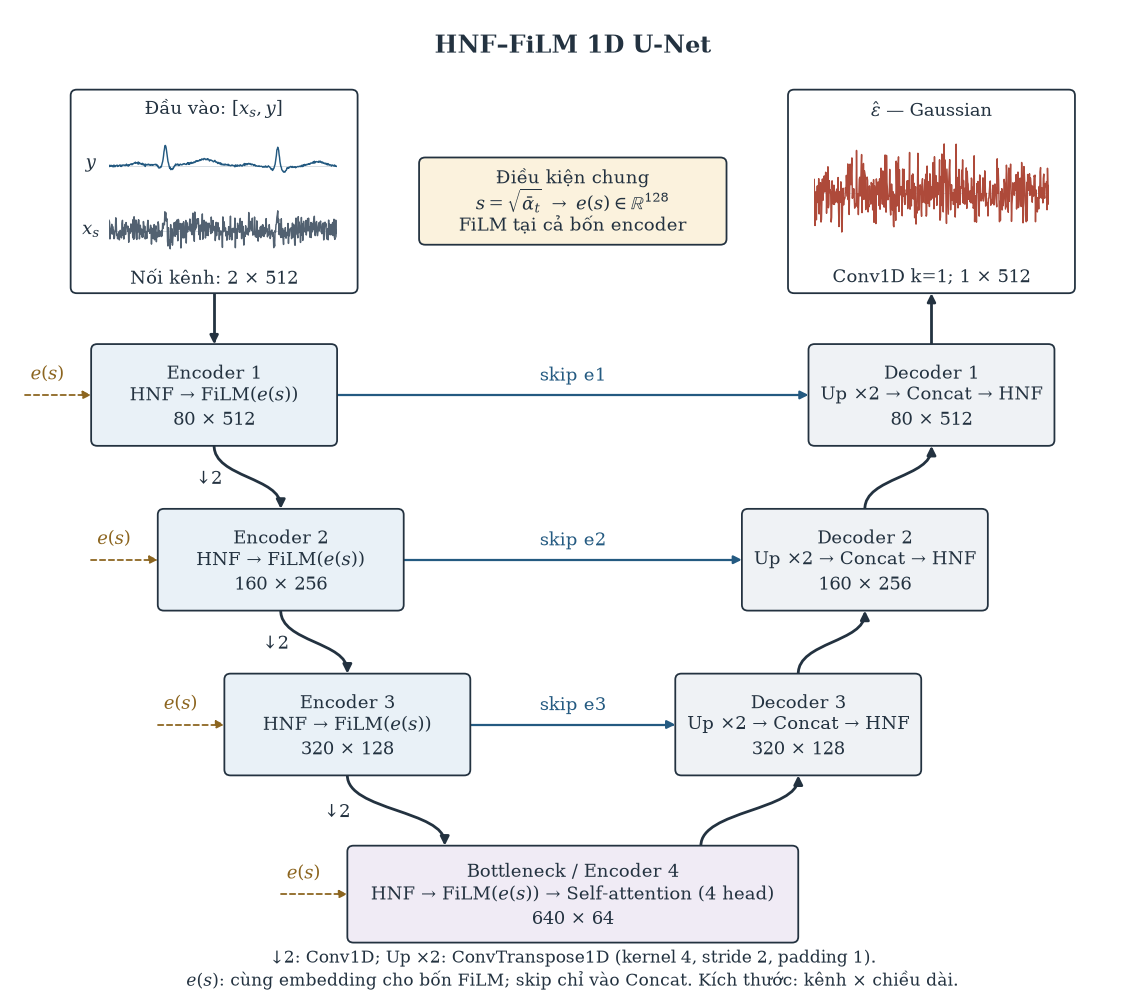

In [24]:
fig = make_architecture_figure()
try:
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=PREVIEW_DPI)
        display(Image(data=buffer.getvalue()))
finally:
    plt.close(fig)  # Không hiện thêm bản trùng cuối cell.


## 6. Xuất và tải hình — tùy chọn

Mặc định Run all chỉ xem hình. Khi chốt bố cục, đặt `EXPORT_FILES=True` rồi chạy riêng cell dưới để xuất `2.png` (600 dpi), `2.pdf`, `2.svg`, bản mô tả và ZIP trong Files của Colab. Chỉ bật thêm `DOWNLOAD_ZIP=True` khi muốn tải về máy. Bước xuất vẽ lại từ cấu hình/hàm hiện hành nên không dùng nhầm preview cũ.

In [25]:
EXPORT_FILES = False
DOWNLOAD_ZIP = False

def export_architecture():
    figure = make_architecture_figure()
    try:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        paths = []
        for extension in ('pdf', 'svg', 'png'):
            path = OUTPUT_DIR / f'{OUTPUT_BASENAME}.{extension}'
            options = {}
            if extension == 'pdf':
                options['metadata'] = {'Title': 'U4 architecture', 'CreationDate': None, 'ModDate': None}
            elif extension == 'svg':
                options['metadata'] = {'Date': None}
            else:
                options['dpi'] = PNG_DPI
            figure.savefig(path, **options)
            paths.append(path)
        specification = {
            'kind': 'method_diagram_not_experimental_result', 'figure': 2,
            'model': MODEL_SPEC, 'source_notebook': SOURCE_NOTEBOOK,
            'source_architecture_sha256': SOURCE_ARCHITECTURE_SHA256,
            'figure_inches': list(figure.get_size_inches()),
            'layout': 'symmetric_u_central_e4_attention_grouped_decoder',
            'signal_mode': SIGNAL_MODE,
            'signals_are_illustrative': SIGNAL_MODE == 'illustration',
            'illustration_seed': ILLUSTRATION_SEED if SIGNAL_MODE == 'illustration' else None,
            'signal_source': str(SIGNALS_NPZ) if SIGNAL_MODE == 'provided' else None,
            'font_scale': FONT_SCALE, 'grayscale': GRAYSCALE, 'png_dpi': PNG_DPI,
            'encoder_x': ENCODER_X, 'decoder_x': DECODER_X, 'level_y': LEVEL_Y,
            'bottleneck_y': BOTTLENECK_Y,
            'skip_sources': 'e1/e2/e3 after FiLM',
            'conditioning': 'sinusoidal embedding -> FiLM at all four encoders',
        }
        spec_path = OUTPUT_DIR / 'figure_specification.json'
        spec_path.write_text(json.dumps(specification, ensure_ascii=False, indent=2), encoding='utf-8')
        paths.append(spec_path)
        zip_path = OUTPUT_DIR / 'fig02_architecture.zip'
        with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
            for path in paths:
                archive.write(path, arcname=path.name)
        for path in paths:
            print(path.name, f'({path.stat().st_size:,} bytes)')
        print('ZIP:', zip_path)
        return zip_path
    finally:
        plt.close(figure)

if EXPORT_FILES:
    zip_path = export_architecture()
    if DOWNLOAD_ZIP:
        try:
            from google.colab import files
        except ImportError:
            print('Ngoài Colab: mở ZIP theo đường dẫn trên.')
        else:
            files.download(str(zip_path))
else:
    print('Chỉ xem trong notebook; chưa xuất/tải file.')


Chỉ xem trong notebook; chưa xuất/tải file.


## 7. Chèn vào paper sau khi chốt hình

Trên Overleaf, tải `2.png` lên thư mục gốc và chèn bằng tên file `{2.png}` (hoặc dùng `{2.pdf}` cho vector). Bản cục bộ có thể lưu trong `output/imgs/` nhờ `graphicspath`. Notebook này **không tự sửa paper** và không thay các ảnh Hình 1 hiện có.

```latex
\begin{figure*}[t]
  \centering
  \includegraphics[width=\textwidth,height=0.85\textheight,keepaspectratio]{2.png}
  \caption{Kiến trúc HNF--FiLM 1D U-Net (U4) cho đoạn ECG 512 điểm.
  Khối giữa đáy gom Encoder 4 và attention; mỗi decoder gom Up, nối skip và HNF.
  Các skip lấy đặc trưng sau FiLM; các nhãn e(s) chỉ cùng embedding điều kiện
  cho cả bốn encoder. Mạng dự đoán nhiễu Gaussian, không phải ECG phục hồi trực tiếp.
  Các waveform tổng hợp chỉ minh họa loại tín hiệu, không phải kết quả thực nghiệm.}
  \label{fig:architecture}
\end{figure*}
```

Trước khi chèn: kiểm tra cỡ chữ ở kích thước in thật, ba skip, bốn nhánh FiLM và các kích thước sau nối kênh. Kiểm tra hình trên Colab sau mỗi lần sửa vị trí khối; notebook không tự điều chỉnh các đường nối thủ công nếu thay đổi bố cục lớn.
